# Akuisisi Data Akomodasi di Kecamatan Kintamani
**BIFP-243 Akuisisi dan Manajemen Data** · Sumber: OpenStreetMap via Overpass API

Data © OpenStreetMap contributors, lisensi ODbL (https://www.openstreetmap.org/copyright).
Data kontak pribadi (telepon, email, media sosial) sengaja **tidak** diambil (minimisasi data).
Berkas di `data/raw/` tidak pernah diubah setelah disimpan.

In [1]:
import json, time, hashlib, re
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt

# ===== ISI IDENTITAS ANDA =====
NAMA = "I Putu Wira Astina Rasmawan"
NIM = "2501010098"
# ==============================

URL = "https://overpass-api.de/api/interpreter"
HEADERS = {"User-Agent": f"INSTIKI-BIFP243-Praktikum/1.0 ({NIM}@instiki.ac.id)"}
ATRIBUSI = "© OpenStreetMap contributors"
REFETCH = False   # True hanya jika memang perlu mengambil ulang (hindari beban server)

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, INTERIM, DOCS, REPORTS = (BASE / p for p in ["data/raw", "data/interim", "docs", "reports"])
for p in (RAW, INTERIM, DOCS, REPORTS):
    p.mkdir(parents=True, exist_ok=True)

print("Folder kerja :", BASE)
print("Pengambil    :", NAMA, NIM)
print("Atribusi     :", ATRIBUSI)

Folder kerja : D:\Materi kuliah\Materi Semester 3\akomodasi_kintamani_2501010098
Pengambil    : I Putu Wira Astina Rasmawan 2501010098
Atribusi     : © OpenStreetMap contributors


In [2]:
QUERY = """[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;"""

# Query pembantu: hanya untuk mengambil kotak batas (bbox) kecamatan sebagai cek koordinat
QUERY_BATAS = """[out:json][timeout:60];
rel["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"];
out bb;"""

(DOCS / "query_overpass.txt").write_text(
    "# Query utama (akomodasi)\n" + QUERY + "\n\n# Query pembantu (batas kecamatan)\n" + QUERY_BATAS + "\n",
    encoding="utf-8")
print(QUERY)
print("\nTersimpan di docs/query_overpass.txt")

[out:json][timeout:90];
area["name"="Kintamani"]["boundary"="administrative"]["admin_level"="6"]->.kec;
nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"](area.kec);
out center tags;

Tersimpan di docs/query_overpass.txt


In [3]:
def ambil_overpass(query, maks_percobaan=4, jeda=5):
    """POST ke Overpass dengan timeout, retry, dan exponential backoff (pola Modul 06)."""
    for percobaan in range(1, maks_percobaan + 1):
        try:
            r = requests.post(URL, data={"data": query}, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                try:
                    data = r.json()
                except ValueError:
                    print(f"[percobaan {percobaan}] respons 200 bukan JSON valid")
                else:
                    if data.get("remark"):
                        print("Catatan server:", data["remark"])
                    return data
            else:
                print(f"[percobaan {percobaan}] status {r.status_code}, tunggu {jeda}s")
                ra = r.headers.get("Retry-After", "")
                if r.status_code == 429 and ra.isdigit():
                    jeda = max(jeda, int(ra))
        except (requests.Timeout, requests.ConnectionError) as e:
            print(f"[percobaan {percobaan}] {type(e).__name__}, tunggu {jeda}s")
        if percobaan < maks_percobaan:
            time.sleep(jeda)
            jeda *= 2
    raise RuntimeError("Gagal mengambil data dari Overpass")


def md5_file(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


def muat_atau_ambil(prefix, query):
    """Pakai berkas mentah terbaru bila ada (supaya notebook bisa dijalankan ulang
    tanpa membebani server). Ambil baru hanya jika belum ada atau REFETCH=True."""
    ada = sorted(RAW.glob(f"{prefix}_*.json"))
    if ada and not REFETCH:
        path = ada[-1]
        print(f"Memakai berkas mentah yang sudah ada: {path.name}")
        return json.loads(path.read_text(encoding="utf-8")), path, False
    data = ambil_overpass(query)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
    path = RAW / f"{prefix}_{stamp}.json"
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Berkas mentah baru disimpan: {path.name}")
    return data, path, True


data, raw_path, baru = muat_atau_ambil("osm_akomodasi_kintamani", QUERY)
print("Jumlah elemen:", len(data["elements"]))
print("Cap waktu basis data OSM:", data.get("osm3s", {}).get("timestamp_osm_base"))

Memakai berkas mentah yang sudah ada: osm_akomodasi_kintamani_20261110_081707.json
Jumlah elemen: 32
Cap waktu basis data OSM: 2026-11-10T08:16:03Z


In [4]:
data_batas, batas_path, baru_batas = muat_atau_ambil("osm_batas_kintamani", QUERY_BATAS)
rel = [e for e in data_batas["elements"] if e["type"] == "relation"]
print("Relasi batas yang cocok:", len(rel), "(harus 1; jika >1, perketat query dan cek di overpass-turbo)")
BBOX = rel[0]["bounds"] if rel else None
print("BBOX kecamatan:", BBOX)

Memakai berkas mentah yang sudah ada: osm_batas_kintamani_20261110_081837.json
Relasi batas yang cocok: 1 (harus 1; jika >1, perketat query dan cek di overpass-turbo)
BBOX kecamatan: {'minlat': -8.3571424, 'minlon': 115.2323202, 'maxlat': -8.1417656, 'maxlon': 115.4589828}


In [5]:
prov_path = DOCS / "provenance.json"
if baru or not prov_path.exists():
    prov = {
        "endpoint": URL,
        "query": QUERY,
        "waktu_akuisisi_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "osm_base_timestamp": data.get("osm3s", {}).get("timestamp_osm_base"),
        "jumlah_elemen": len(data["elements"]),
        "berkas_mentah": raw_path.name,
        "md5": md5_file(raw_path),
        "lisensi": "ODbL 1.0 - " + ATRIBUSI,
        "pengambil": {"nama": NAMA, "nim": NIM},
        "berkas_pendukung": [{
            "tujuan": "kotak batas kecamatan untuk cek koordinat",
            "query": QUERY_BATAS,
            "berkas": batas_path.name,
            "md5": md5_file(batas_path),
        }],
    }
    prov_path.write_text(json.dumps(prov, ensure_ascii=False, indent=2), encoding="utf-8")
    print("provenance.json ditulis")
else:
    prov = json.loads(prov_path.read_text(encoding="utf-8"))
    cocok = prov["md5"] == md5_file(raw_path)
    print("provenance.json sudah ada; MD5 berkas mentah cocok:", cocok)
    assert cocok, "Berkas mentah berbeda dari yang dicatat di provenance!"
print(json.dumps({k: v for k, v in prov.items() if k != "query"}, indent=2, ensure_ascii=False))

provenance.json sudah ada; MD5 berkas mentah cocok: True
{
  "endpoint": "https://overpass-api.de/api/interpreter",
  "waktu_akuisisi_utc": "2026-11-10T08:18:37+00:00",
  "osm_base_timestamp": "2026-11-10T08:16:03Z",
  "jumlah_elemen": 32,
  "berkas_mentah": "osm_akomodasi_kintamani_20261110_081707.json",
  "md5": "c68676a8683208aff1f3f960be9f0764",
  "lisensi": "ODbL 1.0 - © OpenStreetMap contributors",
  "pengambil": {
    "nama": "I Putu Wira Astina Rasmawan",
    "nim": "2501010098"
  },
  "berkas_pendukung": [
    {
      "tujuan": "kotak batas kecamatan untuk cek koordinat",
      "query": "[out:json][timeout:60];\nrel[\"name\"=\"Kintamani\"][\"boundary\"=\"administrative\"][\"admin_level\"=\"6\"];\nout bb;",
      "berkas": "osm_batas_kintamani_20261110_081837.json",
      "md5": "3cd67cd7f6d2af5da7022a42c22c3c49"
    }
  ]
}


In [6]:
def ratakan(elements):
    baris = []
    for e in elements:
        tg = e.get("tags", {})
        pusat = e.get("center", e)   # node: lat/lon langsung; way/relation: di center
        baris.append({
            "osm_type": e["type"], "osm_id": e["id"],
            "nama": tg.get("name"), "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"), "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"), "jumlah_kamar": tg.get("rooms"),
            "website": tg.get("website") or tg.get("contact:website"),
            "url_osm": f"https://www.openstreetmap.org/{e['type']}/{e['id']}",
        })
    return pd.DataFrame(baris)

akomodasi = ratakan(data["elements"])
assert len(akomodasi) == len(data["elements"]), "Ada elemen yang hilang saat diratakan"
print("Baris tabel:", len(akomodasi), "= jumlah elemen mentah:", len(data["elements"]))
print(akomodasi["jenis"].value_counts(dropna=False))
print("Tanpa nama:", akomodasi["nama"].isna().sum())
akomodasi.head()

Baris tabel: 32 = jumlah elemen mentah: 32
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64
Tanpa nama: 1


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,NaN,NaN,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,NaN,NaN,NaN,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,NaN,https://www.openstreetmap.org/node/4297310696


In [7]:
log = []   # catatan keputusan kualitas data -> docs/qc_log.csv

# 1) duplikat
dup = akomodasi.duplicated(["osm_type", "osm_id"], keep=False).sum()
log.append(("duplikat osm_type+osm_id", int(dup), "dihapus (keep first)" if dup else "tidak ada tindakan"))
akomodasi = akomodasi.drop_duplicates(["osm_type", "osm_id"]).reset_index(drop=True)

# 2) nama kosong (TIDAK dihapus; dihitung)
tanpa_nama = int(akomodasi["nama"].isna().sum())
log.append(("tanpa nama", tanpa_nama, "dipertahankan; dilaporkan jumlahnya"))

# 3) koordinat kosong / di luar bbox kecamatan
kosong = int(akomodasi[["lat", "lon"]].isna().any(axis=1).sum())
log.append(("koordinat kosong", kosong, "dipertahankan; ditandai"))
if BBOX:
    luar = akomodasi[(akomodasi.lat < BBOX["minlat"]) | (akomodasi.lat > BBOX["maxlat"]) |
                     (akomodasi.lon < BBOX["minlon"]) | (akomodasi.lon > BBOX["maxlon"])]
    log.append(("koordinat di luar bbox kecamatan", len(luar), "dipertahankan; periksa manual"))
    print("Di luar bbox:"); print(luar[["osm_type", "osm_id", "nama", "lat", "lon"]])

# 4) kolom hampir selalu kosong
persen_kosong = (akomodasi.isna().mean() * 100).round(1)
print("\n% kosong per kolom:"); print(persen_kosong)
for kol, p in persen_kosong.items():
    if p >= 80:
        log.append((f"kolom '{kol}' kosong {p}%", int(akomodasi[kol].isna().sum()), "dipertahankan (sesuai struktur target)"))

qc = pd.DataFrame(log, columns=["pemeriksaan", "jumlah", "keputusan"])
qc.to_csv(DOCS / "qc_log.csv", index=False, encoding="utf-8")
qc

Di luar bbox:
Empty DataFrame
Columns: [osm_type, osm_id, nama, lat, lon]
Index: []

% kosong per kolom:
osm_type          0.0
osm_id            0.0
nama              3.1
jenis             0.0
lat               0.0
lon               0.0
desa            100.0
bintang          96.9
jumlah_kamar     93.8
website          93.8
url_osm           0.0
dtype: float64


,pemeriksaan,jumlah,keputusan
0,duplikat osm_type+osm_id,0,tidak ada tindakan
1,tanpa nama,1,dipertahankan; dilaporkan jumlahnya
2,koordinat kosong,0,dipertahankan; ditandai
3,koordinat di luar bbox kecamatan,0,dipertahankan; periksa manual
4,kolom 'desa' kosong 100.0%,32,dipertahankan (sesuai struktur target)
5,kolom 'bintang' kosong 96.9%,31,dipertahankan (sesuai struktur target)
6,kolom 'jumlah_kamar' kosong 93.8%,30,dipertahankan (sesuai struktur target)
7,kolom 'website' kosong 93.8%,30,dipertahankan (sesuai struktur target)


In [8]:
KOLOM = ["osm_type", "osm_id", "nama", "jenis", "lat", "lon", "desa",
         "bintang", "jumlah_kamar", "website", "url_osm"]
out_csv = INTERIM / "akomodasi_kintamani.csv"
akomodasi[KOLOM].to_csv(out_csv, index=False, encoding="utf-8")
cek = pd.read_csv(out_csv, dtype={"bintang": str, "jumlah_kamar": str})
print("Tersimpan:", out_csv.relative_to(BASE), "| baris:", len(cek), "| kolom:", list(cek.columns))

Tersimpan: data\interim\akomodasi_kintamani.csv | baris: 32 | kolom: ['osm_type', 'osm_id', 'nama', 'jenis', 'lat', 'lon', 'desa', 'bintang', 'jumlah_kamar', 'website', 'url_osm']


In [9]:
ringkas_jenis = akomodasi["jenis"].value_counts().rename_axis("jenis").reset_index(name="jumlah")
ringkas_desa = (akomodasi["desa"].fillna("(tag addr:village kosong)")
                .value_counts().rename_axis("desa").reset_index(name="jumlah"))
print("Per jenis:"); print(ringkas_jenis.to_string(index=False))
print("\nPer desa:"); print(ringkas_desa.to_string(index=False))

Per jenis:
      jenis  jumlah
      hotel      16
guest_house       9
     hostel       4
     chalet       2
      motel       1

Per desa:
                     desa  jumlah
(tag addr:village kosong)      32


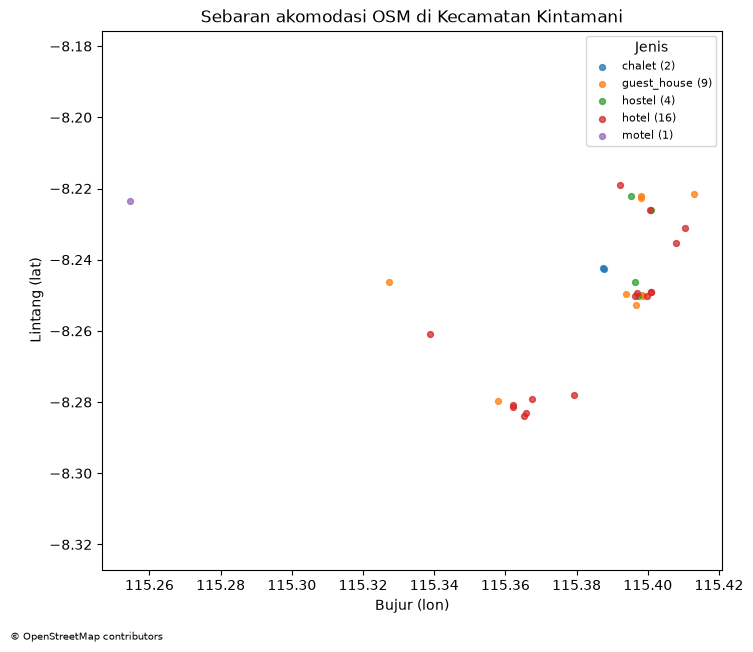

Peta tersimpan di reports/peta_sebaran.png


In [10]:
fig, ax = plt.subplots(figsize=(8, 7))
for jenis, g in akomodasi.dropna(subset=["lat", "lon"]).groupby("jenis"):
    ax.scatter(g["lon"], g["lat"], s=18, alpha=0.75, label=f"{jenis} ({len(g)})")
ax.set_xlabel("Bujur (lon)"); ax.set_ylabel("Lintang (lat)")
ax.set_title("Sebaran akomodasi OSM di Kecamatan Kintamani")
ax.legend(title="Jenis", fontsize=8)
fig.text(0.01, 0.01, ATRIBUSI, fontsize=7)
ax.set_aspect("equal", adjustable="datalim")
fig.savefig(REPORTS / "peta_sebaran.png", dpi=150, bbox_inches="tight")
plt.show()
print("Peta tersimpan di reports/peta_sebaran.png")

In [11]:
# ===== PEMBANDING BPS (Podes 2025) =====
# Tabel 6.1.1 BPS = jumlah DESA yang memiliki sarana akomodasi, BUKAN jumlah usaha.
# Karena itu angkanya dipakai sebagai BATAS BAWAH (minimal 1 usaha per desa), bukan penyebut kelengkapan.
BPS_TAHUN = 2025
BPS_SUMBER = ("Kecamatan Kintamani Dalam Angka 2026, Tabel 6.1.1 hal. 71 (PDF hal. 95); "
              "sumber data BPS Podes 2025; angka = jumlah desa dengan sarana akomodasi")
BPS_DESA = {"Hotel": 4, "Penginapan": 12}
# Asumsi pemetaan jenis OSM -> kategori BPS (jelaskan di laporan):
PEMETAAN = {
    "Hotel": ["hotel"],
    "Penginapan": ["guest_house", "hostel", "motel", "apartment", "chalet"],
}
# =========================================

baris = []
for kat, jenis_osm in PEMETAAN.items():
    sub = akomodasi[akomodasi["jenis"].isin(jenis_osm)]
    batas = BPS_DESA[kat]
    baris.append({
        "kategori": kat, "jenis_osm": "+".join(jenis_osm),
        "jumlah_osm": len(sub), "desa_osm_terisi": int(sub["desa"].dropna().nunique()),
        "objek_osm_tanpa_desa": int(sub["desa"].isna().sum()),
        "bps_desa_dengan_sarana": batas,
        "rasio_osm_terhadap_batas_bawah_persen": round(len(sub) / batas * 100, 1),
        "uji_batas_bawah": "Lolos" if len(sub) >= batas else "TIDAK lolos",
    })
total_osm = sum(b["jumlah_osm"] for b in baris)
total_bps = sum(b["bps_desa_dengan_sarana"] for b in baris)
baris.append({
    "kategori": "TOTAL", "jenis_osm": "semua",
    "jumlah_osm": total_osm,
    "desa_osm_terisi": int(akomodasi["desa"].dropna().nunique()),
    "objek_osm_tanpa_desa": int(akomodasi["desa"].isna().sum()),
    "bps_desa_dengan_sarana": total_bps,
    "rasio_osm_terhadap_batas_bawah_persen": round(total_osm / total_bps * 100, 1),
    "uji_batas_bawah": "Lolos" if total_osm >= total_bps else "TIDAK lolos",
})
hasil_bps = pd.DataFrame(baris)
hasil_bps["tahun_bps"] = BPS_TAHUN
hasil_bps["sumber_bps"] = BPS_SUMBER
hasil_bps["tanggal_akses_osm"] = prov["waktu_akuisisi_utc"]
hasil_bps.to_csv(DOCS / "perbandingan_bps.csv", index=False, encoding="utf-8")

print("CATATAN: ini uji batas bawah, BUKAN persentase kelengkapan (BPS tidak memuat jumlah usaha).")
print("Rasio > 100% berarti OSM memuat lebih banyak objek daripada jumlah desa ber-akomodasi menurut BPS.")
hasil_bps.drop(columns=["sumber_bps", "tanggal_akses_osm"])

CATATAN: ini uji batas bawah, BUKAN persentase kelengkapan (BPS tidak memuat jumlah usaha).
Rasio > 100% berarti OSM memuat lebih banyak objek daripada jumlah desa ber-akomodasi menurut BPS.


,kategori,jenis_osm,jumlah_osm,desa_osm_terisi,objek_osm_tanpa_desa,bps_desa_dengan_sarana,rasio_osm_terhadap_batas_bawah_persen,uji_batas_bawah,tahun_bps
0,Hotel,hotel,16,0,16,4,400.0,Lolos,2025
1,Penginapan,guest_house+hostel+motel+apartment+chalet,16,0,16,12,133.3,Lolos,2025
2,TOTAL,semua,32,0,32,16,200.0,Lolos,2025


In [12]:
sp_path = DOCS / "sampel_verifikasi.csv"
if sp_path.exists():
    sampel = pd.read_csv(sp_path, dtype=str).fillna("")   # jangan timpa isian manual
    print("sampel_verifikasi.csv sudah ada; isian manual dipertahankan.")
else:
    sampel = akomodasi.sample(n=min(10, len(akomodasi)), random_state=243)[
        ["osm_type", "osm_id", "nama", "jenis", "lat", "lon", "url_osm"]].copy()
    for k in ["nama_benar", "jenis_benar", "lokasi_benar", "sumber_verifikasi", "catatan"]:
        sampel[k] = ""
    sampel.to_csv(sp_path, index=False, encoding="utf-8")
    print("Isi kolom kosong di docs/sampel_verifikasi.csv secara manual (situs resmi akomodasi / peta).")
sampel

sampel_verifikasi.csv sudah ada; isian manual dipertahankan.


,osm_type,osm_id,nama,jenis,lat,lon,url_osm,nama_benar,jenis_benar,lokasi_benar,sumber_verifikasi,catatan
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.2831398,115.3658438,https://www.openstreetmap.org/node/1977779907,,,,,
1,node,13284479326,Lava Bali and Hot Spring,hotel,-8.2503106,115.3963742,https://www.openstreetmap.org/node/13284479326,,,,,
2,node,7238422213,Batur Panorama,hotel,-8.2189435,115.3921304,https://www.openstreetmap.org/node/7238422213,,,,,
3,node,4150326329,Guesthouse,hotel,-8.2814556,115.3622232,https://www.openstreetmap.org/node/4150326329,,,,,
4,node,7205318685,Tegal Suci Guest House,guest_house,-8.2214097,115.4129261,https://www.openstreetmap.org/node/7205318685,,,,,
5,node,4297310696,The Cave Hotel,hotel,-8.2807476,115.3620477,https://www.openstreetmap.org/node/4297310696,,,,,
6,node,5668936157,Black Lava Hostel,hostel,-8.2463334,115.3962755,https://www.openstreetmap.org/node/5668936157,,,,,
7,node,7058054537,Segara Hotel,hotel,-8.2780864,115.3791336,https://www.openstreetmap.org/node/7058054537,,,,,
8,node,5181842726,Batur Volcano Guesthouse,guest_house,-8.2495661,115.3938369,https://www.openstreetmap.org/node/5181842726,,,,,
9,node,6451134585,Caldera,hotel,-8.2791389,115.3673639,https://www.openstreetmap.org/node/6451134585,,,,,


## Catatan
- Kelengkapan = jumlah OSM ÷ jumlah BPS × 100%. OSM diisi relawan sehingga hampir pasti tidak lengkap.
- Villa/homestay/losmen umumnya diberi tag berbeda-beda atau tidak ditandai sama sekali di OSM; ini sumber utama data yang terlewat.
- Selalu cantumkan atribusi: © OpenStreetMap contributors.